In [ ]:
import sys, os
sys.path.append(os.path.abspath(".."))   # pour pouvoir importer des fonctions depuis utils qui est à la racine

import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
from torch.utils.data import DataLoader
import os
from utils import moving_average, ImageDataset, random_90_rotation, get_device

In [2]:
device = get_device()
print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [3]:
batch_size = 512
num_epochs = 10
learning_rate = 3e-4
crop_size = 32
num_attributs = 60

In [ ]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(partial_path="../data/dataset_crops/train_32x32", transform=transform)
val_dataset = ImageDataset(partial_path="../data/dataset_crops/val_32x32", transform=transform)

print(f"taille de train_dataset : {len(train_dataset)}   taille de val_dataset : {len(val_dataset)}")

In [5]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [6]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # Charger un modèle préentraîné
# remplacer la dernière couche pour prédire les attributs
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_attributs)

print(f"Total parameters in the model: {sum(p.numel() for p in model.parameters())/1e6:.6f} million")

Total parameters in the model: 11.207292 million


In [7]:
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, fused=True)
criterion = nn.CrossEntropyLoss()

train_loss_list, val_loss_list = [], []
train_acc_list, val_acc_list = [], []

In [8]:
def get_accuracy(split, iterator):
    if split == "train":
        loader = train_loader
    elif split == "val":
        loader = val_loader
    else:
        print("split non définit")
        return None

    model.eval()
    with torch.no_grad():
        try:
            imgs, attributs, _ = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            imgs, attributs, _ = next(iterator)
        imgs, attributs = imgs.to(device), attributs.to(device)
        attributs_preds = model(imgs)
        probs = torch.sigmoid(attributs_preds)
        preds = (probs > 0.5).to(torch.int64)
        n_correct = (preds.view(-1) == attributs.view(-1)).float().sum().item()
        n_total = attributs.shape[0] * num_attributs
    accuracy = n_correct / n_total
    model.train()

    return accuracy, iterator

moyenne sur les 100 dernières valeurs:   train_loss: 5.089841842651367   val_loss: 6.614432334899902   train_acc: 0.8028541803359985   val_acc: 0.7977889776229858


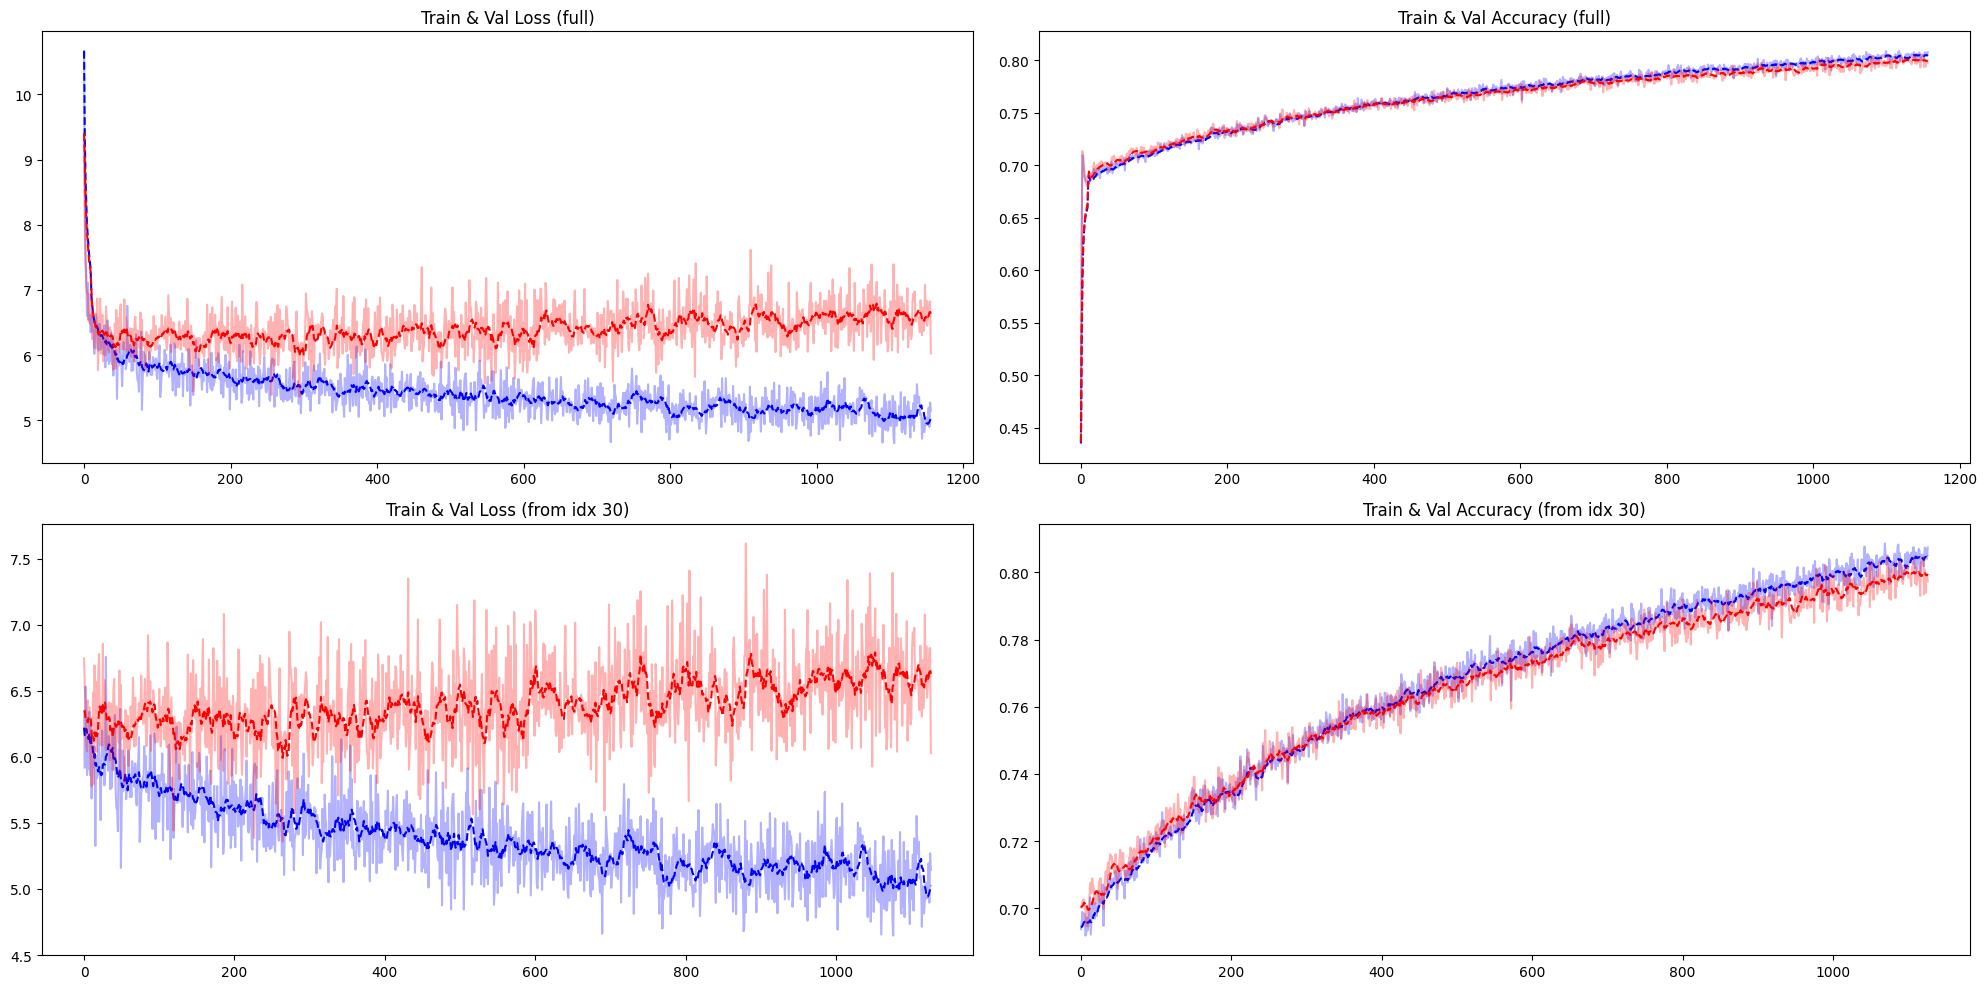

 71%|███████   | 630/889 [02:16<00:56,  4.62it/s]


KeyboardInterrupt: 

In [15]:
for epoch in range(num_epochs):
    for i, (imgs, attributs, _) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, attributs = imgs.to(device), attributs.to(device)

        attributs_preds = model(imgs)
        loss = criterion(attributs_preds, attributs)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()



        if i % 10 == 0:
            train_loss_list.append(loss.item())

            # get val loss
            model.eval()
            with torch.no_grad():
                try:
                    imgs, attributs, _ = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, attributs, _ = next(val_iterator)
                imgs, attributs = imgs.to(device), attributs.to(device)
                attributs_preds = model(imgs)
                loss = criterion(attributs_preds, attributs)
                val_loss_list.append(loss.item())
            model.train()

            # get accuracy
            train_acc, train_iterator = get_accuracy("train", train_iterator)
            val_acc, val_iterator = get_accuracy("val", val_iterator)
            train_acc_list.append(train_acc)
            val_acc_list.append(val_acc)



    train_loss_list_smoothed = moving_average(train_loss_list)
    val_loss_list_smoothed = moving_average(val_loss_list)
    train_acc_list_smoothed = moving_average(train_acc_list)
    val_acc_list_smoothed = moving_average(val_acc_list)

    clear_output(wait=True)  # efface l'ancien plot

    print(f"moyenne sur les 100 dernières valeurs:   train_loss: {torch.tensor([train_loss_list[-100:]]).mean()}   val_loss: {torch.tensor([val_loss_list[-100:]]).mean()}   train_acc: {torch.tensor([train_acc_list[-100:]]).mean()}   val_acc: {torch.tensor([val_acc_list[-100:]]).mean()}")

    plt.figure(figsize=(20, 10))  # plus grand pour 4 sous-plots

    # 1er plot (train+val loss, full)
    plt.subplot(2, 2, 1)
    plt.plot(train_loss_list, c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
    plt.plot(val_loss_list, c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
    plt.title("Train & Val Loss (full)")

    # 2e plot (train+val acc, full)
    plt.subplot(2, 2, 2)
    plt.plot(train_acc_list, c="blue", alpha=0.3)
    plt.plot(train_acc_list_smoothed, c="blue", linestyle='--')
    plt.plot(val_acc_list, c="red", alpha=0.3)
    plt.plot(val_acc_list_smoothed, c="red", linestyle='--')
    plt.title("Train & Val Accuracy (full)")

    # 3e plot (train+val loss, from index 30)
    plt.subplot(2, 2, 3)
    plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
    plt.plot(val_loss_list[30:], c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
    plt.title("Train & Val Loss (from idx 30)")

    # 4e plot (train+val acc, from index 30)
    plt.subplot(2, 2, 4)
    plt.plot(train_acc_list[30:], c="blue", alpha=0.3)
    plt.plot(train_acc_list_smoothed[30:], c="blue", linestyle='--')
    plt.plot(val_acc_list[30:], c="red", alpha=0.3)
    plt.plot(val_acc_list_smoothed[30:], c="red", linestyle='--')
    plt.title("Train & Val Accuracy (from idx 30)")

    plt.tight_layout()  # ajuste l'espacement
    plt.show()


In [ ]:
# # sauvegarder les poids du modèle et les paramètres d'entraînement

# torch.save({
#     'model_state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
#     'optimizer_state_dict': optimizer.state_dict(),
# }, f"weights/imgs_to_attributs_{crop_size}x{crop_size}_checkpoint.pth")